In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.upper() == "NOTEBOOKS":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "DATA" / "PROCESSED"

DELIVERIES_PATH = DATA_PROCESSED_DIR / "deliveries.csv"
MATCHES_PATH = DATA_PROCESSED_DIR / "matches.csv"

OUTPUT_DIR = DATA_PROCESSED_DIR / "ADVANCED_ANALYTICS"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Deliveries file:", DELIVERIES_PATH)
print("Matches file:", MATCHES_PATH)
print("Output directory:", OUTPUT_DIR)

assert DELIVERIES_PATH.exists(), "deliveries.csv not found."
assert MATCHES_PATH.exists(), "matches.csv not found."

Project root: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE
Deliveries file: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\deliveries.csv
Matches file: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\matches.csv
Output directory: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\ADVANCED_ANALYTICS


In [3]:
deliveries_df = pd.read_csv(
    DELIVERIES_PATH,
    low_memory=False
)

matches_df = pd.read_csv(
    MATCHES_PATH,
    low_memory=False
)

print("Deliveries shape:", deliveries_df.shape)
print("Matches shape:", matches_df.shape)

print("Data loaded successfully.")
display(deliveries_df.head())
display(matches_df.head())

Deliveries shape: (295732, 27)
Matches shape: (1243, 26)
Data loaded successfully.


,match_id,season,start_date,venue,innings,ball,actual_delivery,batting_team,bowling_team,striker,non_striker,bowler,runs_off_bat,extras,wides,noballs,byes,legbyes,penalty,non_boundary,wicket_type,player_dismissed,other_wicket_type,other_player_dismissed,fielder_1,fielder_2,fielder_3
0,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.10,0.10,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.20,0.20,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.30,0.30,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.40,0.40,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.50,0.50,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,2,2.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,match_id,season,date,event,match_type,match_number,gender,team_1,team_2,venue,city,toss_winner,toss_decision,player_of_match,winner,winner_runs,winner_wickets,overs,balls_per_over,target_runs,target_overs,team_1_players,team_2_players,umpires,match_referee,info_version
0,1082591,2017.00,2017-04-05,Indian Premier League,T20,1.00,male,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Yuvraj Singh,Sunrisers Hyderabad,35.00,NaN,20,6,208.00,20.00,DA Warner | S Dhawan | MC Henriques | Yuvraj S...,CH Gayle | Mandeep Singh | TM Head | KM Jadhav...,AY Dandekar | NJ Llong,J Srinath,2.3.0
1,1082592,2017.00,2017-04-06,Indian Premier League,T20,2.00,male,Rising Pune Supergiant,Mumbai Indians,Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant,field,SPD Smith,Rising Pune Supergiant,NaN,7.00,20,6,185.00,20.00,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,PA Patel | JC Buttler | RG Sharma | N Rana | A...,A Nand Kishore | S Ravi,M Nayyar,2.3.0
2,1082593,2017.00,2017-04-07,Indian Premier League,T20,3.00,male,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,Rajkot,Kolkata Knight Riders,field,CA Lynn,Kolkata Knight Riders,NaN,10.00,20,6,184.00,20.00,JJ Roy | BB McCullum | SK Raina | AJ Finch | K...,G Gambhir | CA Lynn | RV Uthappa | MK Pandey |...,Nitin Menon | CK Nandan,V Narayan Kutty,2.3.0
3,1082594,2017.00,2017-04-08,Indian Premier League,T20,4.00,male,Kings XI Punjab,Rising Pune Supergiant,Holkar Cricket Stadium,Indore,Kings XI Punjab,field,GJ Maxwell,Kings XI Punjab,NaN,6.00,20,6,164.00,20.00,HM Amla | M Vohra | WP Saha | AR Patel | GJ Ma...,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,AK Chaudhary | C Shamshuddin,Chinmay Sharma,2.3.0
4,1082595,2017.00,2017-04-08,Indian Premier League,T20,5.00,male,Royal Challengers Bangalore,Delhi Daredevils,M.Chinnaswamy Stadium,Bengaluru,Royal Challengers Bangalore,bat,KM Jadhav,Royal Challengers Bangalore,15.00,NaN,20,6,158.00,20.00,CH Gayle | SR Watson | Mandeep Singh | KM Jadh...,AP Tare | SW Billings | KK Nair | SV Samson | ...,S Ravi | VK Sharma,J Srinath,2.3.0


In [4]:
required_delivery_columns = [
    "match_id",
    "season",
    "innings",
    "batting_team",
    "bowling_team",
    "striker",
    "bowler",
    "runs_off_bat",
    "extras",
    "wides",
    "noballs",
    "wicket_type",
    "player_dismissed",
    "ball"
]

required_match_columns = [
    "match_id",
    "season",
    "player_of_match",
    "winner",
    "winner_runs",
    "winner_wickets"
]

missing_delivery_columns = [
    col for col in required_delivery_columns
    if col not in deliveries_df.columns
]

missing_match_columns = [
    col for col in required_match_columns
    if col not in matches_df.columns
]

assert not missing_delivery_columns, (
    f"Missing delivery columns: {missing_delivery_columns}"
)

assert not missing_match_columns, (
    f"Missing match columns: {missing_match_columns}"
)

deliveries = deliveries_df.copy()
matches = matches_df.copy()

numeric_columns = [
    "innings",
    "ball",
    "runs_off_bat",
    "extras",
    "wides",
    "noballs"
]

for col in numeric_columns:
    deliveries[col] = pd.to_numeric(
        deliveries[col], errors="coerce"
    )

for col in ["winner_runs", "winner_wickets"]:
    matches[col] = pd.to_numeric(
        matches[col], errors="coerce"
    )

deliveries["runs_off_bat"] = deliveries["runs_off_bat"].fillna(0)
deliveries["extras"] = deliveries["extras"].fillna(0)
deliveries["wides"] = deliveries["wides"].fillna(0)
deliveries["noballs"] = deliveries["noballs"].fillna(0)

# Total team runs on each delivery.
deliveries["total_runs"] = (
    deliveries["runs_off_bat"] + deliveries["extras"]
)

# Batter balls faced: wides are excluded.
deliveries["ball_faced"] = (
    deliveries["wides"].eq(0).astype(int)
)

# Legal balls for bowling statistics: wides and no-balls excluded.
deliveries["legal_ball"] = (
    deliveries["wides"].eq(0)
    & deliveries["noballs"].eq(0)
).astype(int)

# Count boundaries scored by the batter, not extras.
deliveries["is_four"] = (
    deliveries["runs_off_bat"].eq(4)
    & deliveries.get(
        "non_boundary", pd.Series(0, index=deliveries.index)
    ).fillna(0).eq(0)
).astype(int)

deliveries["is_six"] = (
    deliveries["runs_off_bat"].eq(6)
    & deliveries.get(
        "non_boundary", pd.Series(0, index=deliveries.index)
    ).fillna(0).eq(0)
).astype(int)

print("Data preparation completed.")
display(deliveries.head())

Data preparation completed.


,match_id,season,start_date,venue,innings,ball,actual_delivery,batting_team,bowling_team,striker,non_striker,bowler,runs_off_bat,extras,wides,noballs,byes,legbyes,penalty,non_boundary,wicket_type,player_dismissed,other_wicket_type,other_player_dismissed,fielder_1,fielder_2,fielder_3,total_runs,ball_faced,legal_ball,is_four,is_six
0,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.10,0.10,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,0,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,1,0,0
1,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.20,0.20,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,0,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,1,0,0
2,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.30,0.30,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,4,0,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,1,1,1,0
3,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.40,0.40,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,0,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,1,0,0
4,1082591,2017.00,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.50,0.50,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,S Dhawan,TS Mills,0,2,2.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0,0,0,0


,batter_runs,deliveries,total_batter_runs,delivery_percentage
0,0,116759,0,39.48
1,1,109492,109492,37.02
2,2,18338,36676,6.20
3,3,843,2529,0.29
4,4,34447,137788,11.65
5,5,74,370,0.03
6,6,15779,94674,5.34


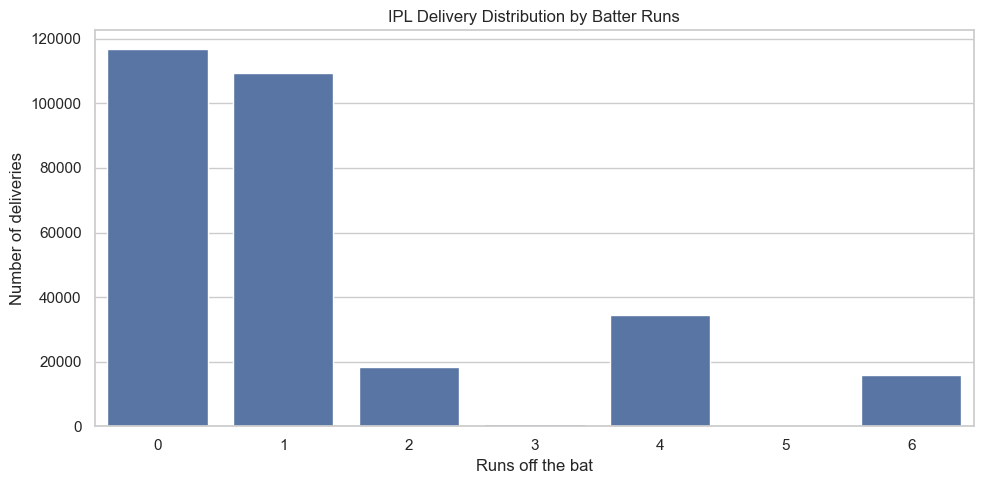

In [5]:
scoring_pattern = (
    deliveries.groupby("runs_off_bat")
    .agg(
        deliveries=("runs_off_bat", "size"),
        total_batter_runs=("runs_off_bat", "sum")
    )
    .reset_index()
    .rename(columns={"runs_off_bat": "batter_runs"})
    .sort_values("batter_runs")
)

scoring_pattern["delivery_percentage"] = (
    scoring_pattern["deliveries"]
    / scoring_pattern["deliveries"].sum()
    * 100
)

display(scoring_pattern)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=scoring_pattern,
    x="batter_runs",
    y="deliveries"
)
plt.title("IPL Delivery Distribution by Batter Runs")
plt.xlabel("Runs off the bat")
plt.ylabel("Number of deliveries")
plt.tight_layout()
plt.show()

,run_category,deliveries,total_runs,percentage_of_deliveries
2,One run,122972,122972,41.58
0,Dot ball,101230,0,34.23
1,Four,34426,137861,11.64
7,Two runs,19311,38622,6.53
5,Six,15771,94721,5.33
3,Other scoring,1031,4585,0.35
6,Three runs,990,2970,0.33
4,Seven or more,1,7,0.00


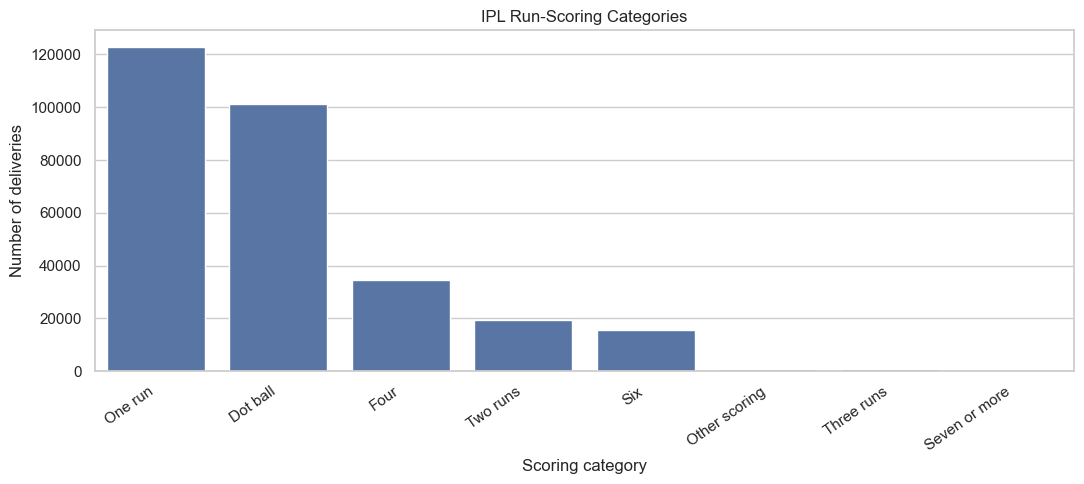

In [6]:
deliveries["run_category"] = np.select(
    [
        deliveries["total_runs"].eq(0),
        deliveries["total_runs"].eq(1),
        deliveries["total_runs"].eq(2),
        deliveries["total_runs"].eq(3),
        deliveries["is_four"].eq(1),
        deliveries["is_six"].eq(1),
        deliveries["total_runs"].ge(7)
    ],
    [
        "Dot ball",
        "One run",
        "Two runs",
        "Three runs",
        "Four",
        "Six",
        "Seven or more"
    ],
    default="Other scoring"
)

run_category_summary = (
    deliveries.groupby("run_category")
    .agg(
        deliveries=("match_id", "size"),
        total_runs=("total_runs", "sum")
    )
    .reset_index()
)

run_category_summary["percentage_of_deliveries"] = (
    run_category_summary["deliveries"]
    / run_category_summary["deliveries"].sum()
    * 100
)

display(
    run_category_summary.sort_values(
        "deliveries", ascending=False
    )
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=run_category_summary.sort_values(
        "deliveries", ascending=False
    ),
    x="run_category",
    y="deliveries"
)
plt.title("IPL Run-Scoring Categories")
plt.xlabel("Scoring category")
plt.ylabel("Number of deliveries")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [7]:
print("Sample ball values:")
display(deliveries["ball"].dropna().drop_duplicates().head(15))

deliveries["over_number"] = np.floor(
    deliveries["ball"]
).astype("Int64")

deliveries["match_phase"] = np.select(
    [
        deliveries["over_number"].between(0, 5).fillna(False),
        deliveries["over_number"].between(6, 14).fillna(False),
        deliveries["over_number"].ge(15).fillna(False)
    ],
    [
        "Powerplay",
        "Middle Overs",
        "Death Overs"
    ],
    default="Unknown"
)

phase_summary = (
    deliveries[deliveries["match_phase"] != "Unknown"]
    .groupby("match_phase")
    .agg(
        deliveries=("match_id", "size"),
        team_runs=("total_runs", "sum"),
        batter_runs=("runs_off_bat", "sum"),
        fours=("is_four", "sum"),
        sixes=("is_six", "sum"),
        legal_balls=("legal_ball", "sum")
    )
    .reset_index()
)

phase_summary["runs_per_legal_ball"] = (
    phase_summary["team_runs"]
    / phase_summary["legal_balls"].replace(0, np.nan)
)

phase_summary["boundary_runs"] = (
    phase_summary["fours"] * 4
    + phase_summary["sixes"] * 6
)

phase_summary["boundary_run_percentage"] = (
    phase_summary["boundary_runs"]
    / phase_summary["team_runs"].replace(0, np.nan)
    * 100
)

display(phase_summary)

Sample ball values:


0    0.10
1    0.20
2    0.30
3    0.40
4    0.50
5    0.60
6    0.70
7    1.10
8    1.20
9    1.30
10   1.40
11   1.50
12   1.60
13   1.70
14   2.10
Name: ball, dtype: float64

,match_phase,deliveries,team_runs,batter_runs,fours,sixes,legal_balls,runs_per_legal_ball,boundary_runs,boundary_run_percentage
0,Death Overs,67173,106952,101284,7729,5506,63786,1.68,63952,59.80
1,Middle Overs,135655,174283,166711,12265,6482,131526,1.33,87952,50.47
2,Powerplay,92904,120503,113534,14432,3783,89318,1.35,80426,66.74


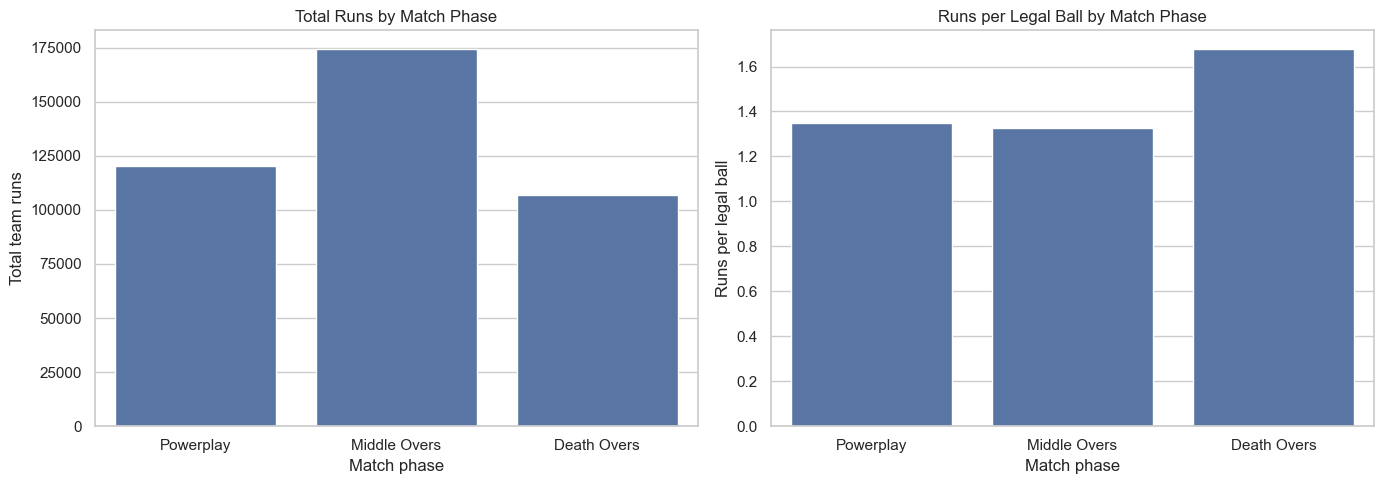

In [8]:
phase_order = ["Powerplay", "Middle Overs", "Death Overs"]

phase_plot = phase_summary.set_index(
    "match_phase"
).reindex(phase_order).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=phase_plot,
    x="match_phase",
    y="team_runs",
    ax=axes[0]
)
axes[0].set_title("Total Runs by Match Phase")
axes[0].set_xlabel("Match phase")
axes[0].set_ylabel("Total team runs")

sns.barplot(
    data=phase_plot,
    x="match_phase",
    y="runs_per_legal_ball",
    ax=axes[1]
)
axes[1].set_title("Runs per Legal Ball by Match Phase")
axes[1].set_xlabel("Match phase")
axes[1].set_ylabel("Runs per legal ball")

plt.tight_layout()
plt.show()

,player_of_match,awards,seasons
11,AB de Villiers,25,10
47,CH Gayle,22,8
304,V Kohli,22,10
237,RG Sharma,21,11
59,DA Warner,18,9
182,MS Dhoni,18,10
273,SP Narine,18,8
132,KL Rahul,17,7
231,RA Jadeja,17,9
16,AD Russell,16,8


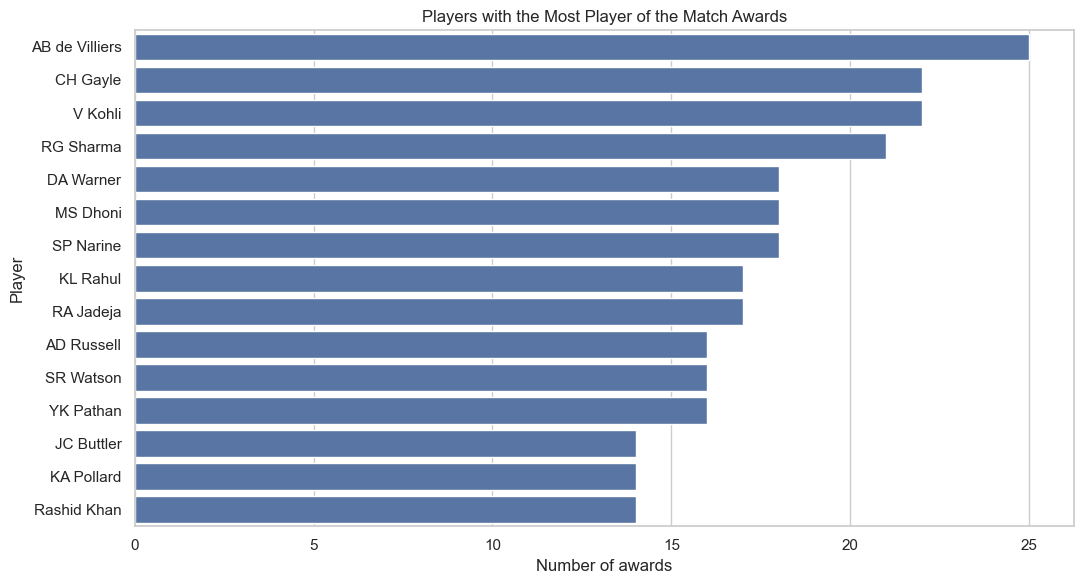

In [9]:
pom_df = matches[
    matches["player_of_match"].notna()
    & matches["player_of_match"].astype(str).str.strip().ne("")
].copy()

pom_summary = (
    pom_df.groupby("player_of_match")
    .agg(
        awards=("match_id", "nunique"),
        seasons=("season", "nunique")
    )
    .reset_index()
    .sort_values(
        ["awards", "player_of_match"],
        ascending=[False, True]
    )
)

top_pom_players = pom_summary.head(15)

display(top_pom_players)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=top_pom_players,
    x="awards",
    y="player_of_match"
)
plt.title("Players with the Most Player of the Match Awards")
plt.xlabel("Number of awards")
plt.ylabel("Player")
plt.tight_layout()
plt.show()

In [10]:
pom_by_season = (
    pom_df.groupby(["season", "player_of_match"])
    .agg(awards=("match_id", "nunique"))
    .reset_index()
)

pom_by_season["season"] = pom_by_season["season"].astype(str)

top_pom_by_season = (
    pom_by_season.sort_values(
        ["season", "awards", "player_of_match"],
        ascending=[True, False, True]
    )
    .groupby("season", as_index=False)
    .head(1)
    .sort_values("season")
)

display(top_pom_by_season)

,season,player_of_match,awards
40,2009.0,YK Pathan,3
49,2011.0,CH Gayle,6
104,2012.0,CH Gayle,5
169,2013.0,MEK Hussey,5
201,2014.0,GJ Maxwell,4
235,2015.0,DA Warner,4
302,2016.0,V Kohli,5
308,2017.0,BA Stokes,3
378,2018.0,Rashid Khan,4
391,2019.0,AD Russell,4


In [11]:
# Batting statistics
batting_stats = (
    deliveries.groupby("striker")
    .agg(
        batting_runs=("runs_off_bat", "sum"),
        balls_faced=("ball_faced", "sum"),
        fours=("is_four", "sum"),
        sixes=("is_six", "sum"),
        batting_matches=("match_id", "nunique")
    )
    .reset_index()
    .rename(columns={"striker": "player"})
)

batting_stats["strike_rate"] = (
    batting_stats["batting_runs"]
    / batting_stats["balls_faced"].replace(0, np.nan)
    * 100
)

# Bowler-conceded runs convention:
# batter runs + wides + no-balls.
deliveries["bowler_conceded_runs"] = (
    deliveries["runs_off_bat"]
    + deliveries["wides"]
    + deliveries["noballs"]
)

# Wicket types credited to the bowler.
bowler_credited_types = {
    "bowled",
    "caught",
    "caught and bowled",
    "lbw",
    "stumped",
    "hit wicket",
    "hit the ball twice"
}

deliveries["wicket_type_clean"] = (
    deliveries["wicket_type"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

deliveries["bowler_credited_wicket"] = (
    deliveries["wicket_type_clean"]
    .isin(bowler_credited_types)
    & deliveries["player_dismissed"].notna()
).astype(int)

bowling_stats = (
    deliveries.groupby("bowler")
    .agg(
        runs_conceded=("bowler_conceded_runs", "sum"),
        legal_balls=("legal_ball", "sum"),
        wickets=("bowler_credited_wicket", "sum"),
        bowling_matches=("match_id", "nunique")
    )
    .reset_index()
    .rename(columns={"bowler": "player"})
)

bowling_stats["economy"] = (
    bowling_stats["runs_conceded"]
    / (bowling_stats["legal_balls"] / 6).replace(0, np.nan)
)

bowling_stats["bowling_average"] = (
    bowling_stats["runs_conceded"]
    / bowling_stats["wickets"].replace(0, np.nan)
)

all_rounder_stats = batting_stats.merge(
    bowling_stats,
    on="player",
    how="outer"
)

numeric_stat_columns = [
    "batting_runs",
    "balls_faced",
    "fours",
    "sixes",
    "batting_matches",
    "runs_conceded",
    "legal_balls",
    "wickets",
    "bowling_matches"
]

all_rounder_stats[numeric_stat_columns] = (
    all_rounder_stats[numeric_stat_columns].fillna(0)
)

all_rounder_stats["matches_in_either_discipline"] = (
    all_rounder_stats[
        ["batting_matches", "bowling_matches"]
    ].max(axis=1)
)

# Filter out players with only very limited involvement.
all_rounder_stats_filtered = all_rounder_stats[
    (all_rounder_stats["batting_runs"] >= 100)
    & (all_rounder_stats["wickets"] >= 5)
].copy()

all_rounder_stats_filtered = (
    all_rounder_stats_filtered.sort_values(
        ["batting_runs", "wickets"],
        ascending=[False, False]
    )
)

display(all_rounder_stats_filtered.head(30))

,player,batting_runs,balls_faced,fours,sixes,batting_matches,strike_rate,runs_conceded,legal_balls,wickets,bowling_matches,economy,bowling_average,matches_in_either_discipline
571,RG Sharma,7331.00,5517.00,661.00,323.00,275.00,132.88,453.00,339.00,15.00,32.00,8.02,30.20,275.00
651,SK Raina,5536.00,4046.00,506.00,204.00,200.00,136.83,1118.00,908.00,25.00,69.00,7.39,44.72,200.00
146,CH Gayle,4997.00,3346.00,407.00,359.00,141.00,149.34,729.00,554.00,18.00,38.00,7.90,40.50,141.00
672,SR Watson,3880.00,2813.00,377.00,190.00,141.00,137.93,2682.00,2029.00,92.00,105.00,7.93,29.15,141.00
562,RA Jadeja,3526.00,2699.00,264.00,122.00,205.00,130.64,5465.00,4254.00,180.00,237.00,7.71,30.36,237.00
327,KA Pollard,3437.00,2329.00,221.00,224.00,168.00,147.57,2180.00,1488.00,69.00,107.00,8.79,31.59,168.00
794,YK Pathan,3222.00,2245.00,263.00,160.00,153.00,143.52,1415.00,1147.00,42.00,82.00,7.40,33.69,153.00
469,N Rana,3078.00,2235.00,288.00,151.00,121.00,137.72,325.00,216.00,10.00,27.00,9.03,32.50,121.00
250,HH Pandya,2964.00,2025.00,228.00,156.00,150.00,146.37,2751.00,1764.00,82.00,116.00,9.36,33.55,150.00
235,GJ Maxwell,2820.00,1818.00,237.00,161.00,134.00,155.12,1413.00,1022.00,41.00,85.00,8.30,34.46,134.00


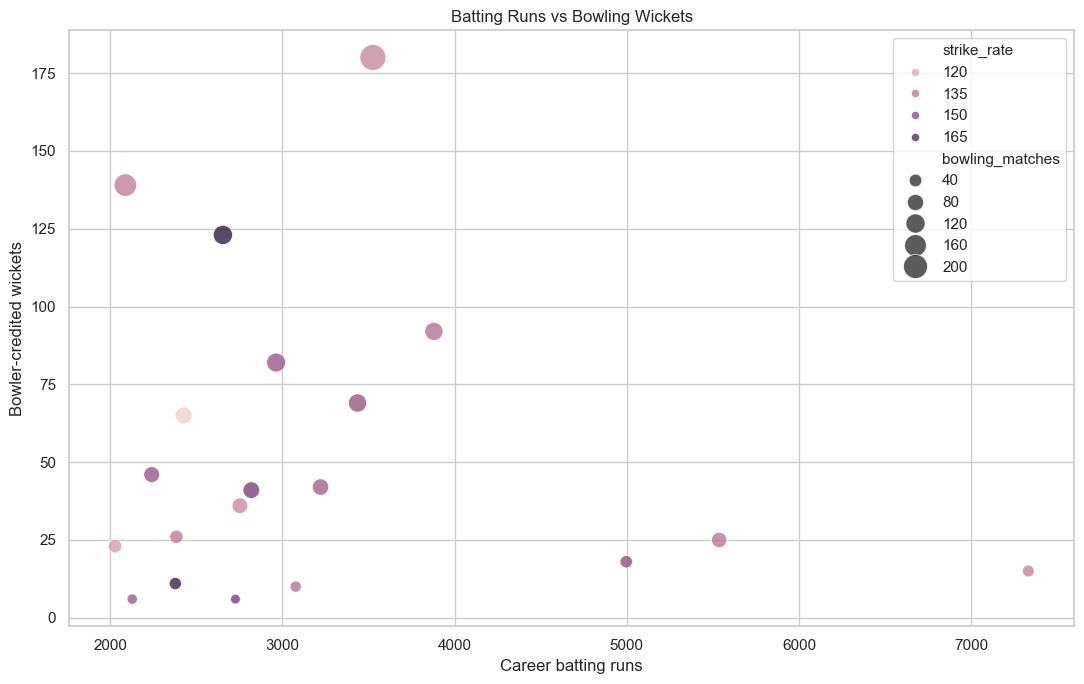

In [12]:
plot_df = all_rounder_stats_filtered.head(20).copy()

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=plot_df,
    x="batting_runs",
    y="wickets",
    size="bowling_matches",
    hue="strike_rate",
    sizes=(50, 350),
    alpha=0.8
)

plt.title("Batting Runs vs Bowling Wickets")
plt.xlabel("Career batting runs")
plt.ylabel("Bowler-credited wickets")
plt.tight_layout()
plt.show()

,margin_category,matches
2,Larger margin / other,648
4,Win by wickets (3–5),213
3,Win by runs (11–30),208
0,Close win by runs (1–10),132
1,Close win by wickets (1–2),17


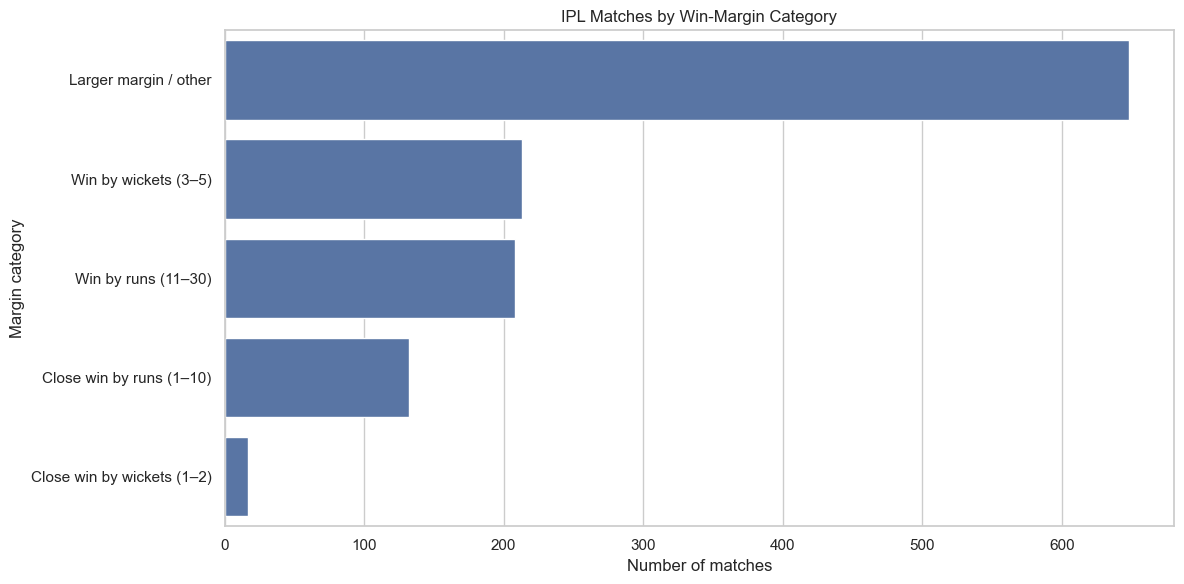

In [13]:
decided_matches = matches[
    matches["winner"].notna()
    & matches["winner"].astype(str).str.strip().ne("")
].copy()

decided_matches["result_type"] = np.select(
    [
        decided_matches["winner_runs"].notna()
        & decided_matches["winner_runs"].gt(0),

        decided_matches["winner_wickets"].notna()
        & decided_matches["winner_wickets"].gt(0)
    ],
    [
        "Win by runs",
        "Win by wickets"
    ],
    default="Other/Unspecified"
)

decided_matches["margin_category"] = np.select(
    [
        decided_matches["result_type"].eq("Win by runs")
        & decided_matches["winner_runs"].le(10),

        decided_matches["result_type"].eq("Win by runs")
        & decided_matches["winner_runs"].between(11, 30),

        decided_matches["result_type"].eq("Win by wickets")
        & decided_matches["winner_wickets"].le(2),

        decided_matches["result_type"].eq("Win by wickets")
        & decided_matches["winner_wickets"].between(3, 5)
    ],
    [
        "Close win by runs (1–10)",
        "Win by runs (11–30)",
        "Close win by wickets (1–2)",
        "Win by wickets (3–5)"
    ],
    default="Larger margin / other"
)

close_match_summary = (
    decided_matches.groupby("margin_category")
    .agg(matches=("match_id", "nunique"))
    .reset_index()
    .sort_values("matches", ascending=False)
)

display(close_match_summary)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=close_match_summary,
    x="matches",
    y="margin_category"
)
plt.title("IPL Matches by Win-Margin Category")
plt.xlabel("Number of matches")
plt.ylabel("Margin category")
plt.tight_layout()
plt.show()

In [14]:
season_scoring = (
    deliveries.groupby("season")
    .agg(
        total_runs=("total_runs", "sum"),
        batter_runs=("runs_off_bat", "sum"),
        deliveries=("match_id", "size"),
        legal_balls=("legal_ball", "sum"),
        fours=("is_four", "sum"),
        sixes=("is_six", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
    .sort_values("season")
)

season_scoring["runs_per_legal_ball"] = (
    season_scoring["total_runs"]
    / season_scoring["legal_balls"].replace(0, np.nan)
)

season_scoring["boundaries"] = (
    season_scoring["fours"] + season_scoring["sixes"]
)

season_scoring["boundary_runs"] = (
    season_scoring["fours"] * 4
    + season_scoring["sixes"] * 6
)

season_scoring["boundary_run_percentage"] = (
    season_scoring["boundary_runs"]
    / season_scoring["total_runs"].replace(0, np.nan)
    * 100
)

display(season_scoring)

,season,total_runs,batter_runs,deliveries,legal_balls,fours,sixes,matches,runs_per_legal_ball,boundaries,boundary_runs,boundary_run_percentage
0,2009.00,16353,15376,13606,13095,1320,508,57,1.25,1828,8328,50.93
1,2011.00,21154,19928,17013,16425,1913,639,73,1.29,2552,11486,54.30
2,2012.00,22453,21323,17767,17208,1911,731,74,1.30,2642,12030,53.58
3,2013.00,22602,21487,18177,17637,2053,680,76,1.28,2733,12292,54.38
4,2014.00,18931,17943,14300,13845,1563,715,60,1.37,2278,10542,55.69
5,2015.00,18353,17427,13652,13150,1611,692,59,1.40,2303,10596,57.73
6,2016.00,18862,17962,14096,13618,1632,638,60,1.39,2270,10356,54.90
7,2017.00,18786,17920,13862,13401,1610,706,59,1.40,2316,10676,56.83
8,2018.00,19901,19098,14286,13808,1651,872,60,1.44,2523,11836,59.47
9,2019.00,19434,18607,14312,13856,1654,786,60,1.40,2440,11332,58.31


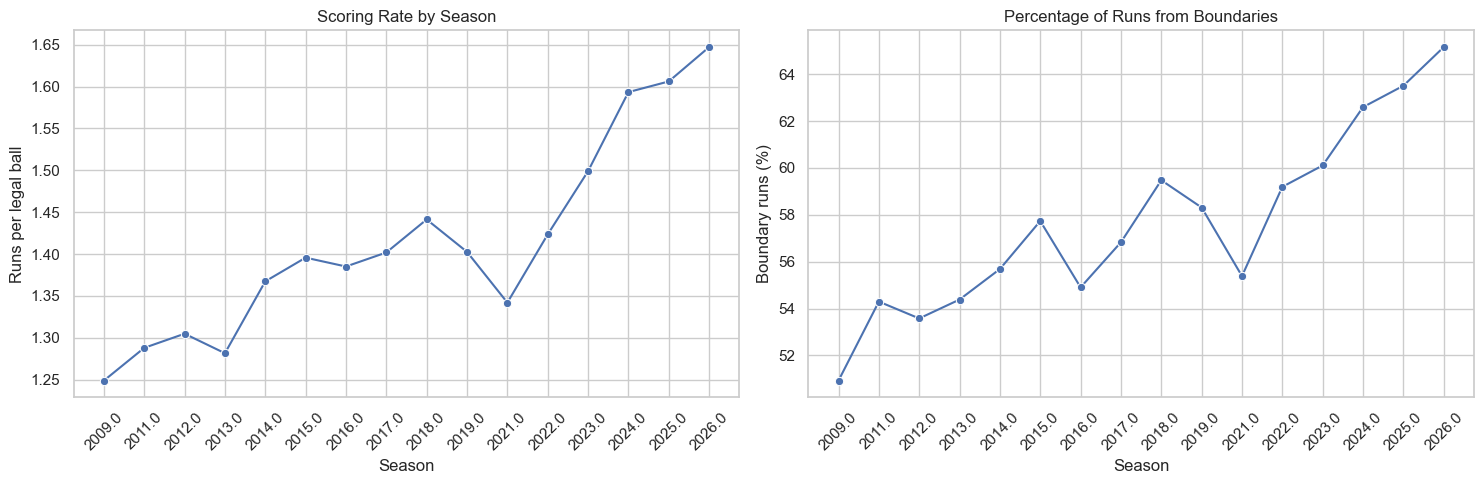

In [15]:
season_plot = season_scoring.copy()
season_plot["season_label"] = season_plot["season"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=season_plot,
    x="season_label",
    y="runs_per_legal_ball",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Scoring Rate by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Runs per legal ball")
axes[0].tick_params(axis="x", rotation=45)

sns.lineplot(
    data=season_plot,
    x="season_label",
    y="boundary_run_percentage",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Percentage of Runs from Boundaries")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Boundary runs (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [16]:
season_player_runs = (
    deliveries.groupby(["season", "striker"])
    .agg(
        runs=("runs_off_bat", "sum"),
        balls_faced=("ball_faced", "sum"),
        fours=("is_four", "sum"),
        sixes=("is_six", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

season_player_runs["strike_rate"] = (
    season_player_runs["runs"]
    / season_player_runs["balls_faced"].replace(0, np.nan)
    * 100
)

season_player_runs = season_player_runs.rename(
    columns={"striker": "player"}
)

top_scorer_per_season = (
    season_player_runs.sort_values(
        ["season", "runs", "player"],
        ascending=[True, False, True]
    )
    .groupby("season", as_index=False)
    .head(1)
    .sort_values("season")
)

display(top_scorer_per_season)

,season,player,runs,balls_faced,fours,sixes,matches,strike_rate
75,2009.00,ML Hayden,572,395,60,22,12,144.81
184,2011.00,CH Gayle,608,332,56,44,12,183.13
366,2012.00,CH Gayle,733,456,46,59,14,160.75
592,2013.00,MEK Hussey,733,566,81,17,17,129.51
770,2014.00,RV Uthappa,660,479,74,18,16,137.79
830,2015.00,DA Warner,562,359,65,21,14,156.55
1065,2016.00,V Kohli,973,640,83,38,16,152.03
1104,2017.00,DA Warner,641,452,63,26,14,141.81
1276,2018.00,KS Williamson,735,516,63,28,17,142.44
1376,2019.00,DA Warner,692,481,57,21,12,143.87


In [17]:
print("DELIVERIES VALIDATION")
print("-" * 50)

print("Total delivery records:", len(deliveries))
print("Unique matches in deliveries:", deliveries["match_id"].nunique())
print("Missing match IDs:", deliveries["match_id"].isna().sum())
print("Missing striker names:", deliveries["striker"].isna().sum())
print("Missing bowler names:", deliveries["bowler"].isna().sum())
print("Negative batter runs:", deliveries["runs_off_bat"].lt(0).sum())
print("Negative extras:", deliveries["extras"].lt(0).sum())
print("Missing/invalid over numbers:", deliveries["over_number"].isna().sum())

print("\nMATCH VALIDATION")
print("-" * 50)

print("Total match records:", len(matches))
print("Unique match IDs:", matches["match_id"].nunique())
print("Missing winners:", matches["winner"].isna().sum())
print("Missing Player of the Match:", matches["player_of_match"].isna().sum())

print("\nPHASE VALIDATION")
print("-" * 50)

display(
    deliveries["match_phase"]
    .value_counts(dropna=False)
    .rename_axis("phase")
    .reset_index(name="deliveries")
)

assert len(deliveries) > 0, "No delivery records loaded."
assert len(matches) > 0, "No match records loaded."

print("\nBasic validation completed.")

DELIVERIES VALIDATION
--------------------------------------------------
Total delivery records: 295732
Unique matches in deliveries: 1243
Missing match IDs: 0
Missing striker names: 0
Missing bowler names: 0
Negative batter runs: 0
Negative extras: 0
Missing/invalid over numbers: 0

MATCH VALIDATION
--------------------------------------------------
Total match records: 1243
Unique match IDs: 1243
Missing winners: 25
Missing Player of the Match: 9

PHASE VALIDATION
--------------------------------------------------


,phase,deliveries
0,Middle Overs,135655
1,Powerplay,92904
2,Death Overs,67173



Basic validation completed.


In [18]:
exports = {
    "run_scoring_patterns.csv": scoring_pattern,
    "run_category_summary.csv": run_category_summary,
    "phase_scoring_summary.csv": phase_summary,
    "player_of_match_awards.csv": pom_summary,
    "player_of_match_by_season.csv": pom_by_season,
    "top_player_of_match_per_season.csv": top_pom_by_season,
    "all_rounder_statistics.csv": all_rounder_stats,
    "close_match_summary.csv": close_match_summary,
    "match_margin_analysis.csv": decided_matches,
    "season_scoring_trends.csv": season_scoring,
    "season_player_batting_statistics.csv": season_player_runs,
    "top_scorer_per_season.csv": top_scorer_per_season
}

for filename, dataframe in exports.items():
    output_path = OUTPUT_DIR / filename
    dataframe.to_csv(output_path, index=False)
    print(f"Saved: {output_path}")

print("\nAll advanced analytics CSV files exported.")

Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\ADVANCED_ANALYTICS\run_scoring_patterns.csv
Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\ADVANCED_ANALYTICS\run_category_summary.csv
Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\ADVANCED_ANALYTICS\phase_scoring_summary.csv
Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\ADVANCED_ANALYTICS\player_of_match_awards.csv
Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\ADVANCED_ANALYTICS\player_of_match_by_season.csv
Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\ADVANCED_ANALYTICS\top_player_of_match_per_season.csv
Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\ADVANCED_ANALYTICS\all_rounder_statistics.csv
Saved: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PR

In [19]:
print("=" * 65)
print("IPL ADVANCED ANALYTICS — PROJECT SUMMARY")
print("=" * 65)

print(f"Matches in match dataset: {matches['match_id'].nunique():,}")
print(f"Delivery records: {len(deliveries):,}")
print(f"Unique batting players: {deliveries['striker'].nunique():,}")
print(f"Unique bowlers: {deliveries['bowler'].nunique():,}")
print(f"Players with Player of the Match awards: {pom_summary['player_of_match'].nunique():,}")
print(f"Players meeting all-rounder filters: {len(all_rounder_stats_filtered):,}")
print(f"Seasons represented: {deliveries['season'].nunique():,}")

print("\nTop run scorer in each season:")
display(
    top_scorer_per_season[
        ["season", "player", "runs", "strike_rate", "matches"]
    ].reset_index(drop=True)
)

print("\nTop Player of the Match award recipients:")
display(pom_summary.head(10).reset_index(drop=True))

print("\nOutput folder:")
print(OUTPUT_DIR)

IPL ADVANCED ANALYTICS — PROJECT SUMMARY
Matches in match dataset: 1,243
Delivery records: 295,732
Unique batting players: 739
Unique bowlers: 578
Players with Player of the Match awards: 321
Players meeting all-rounder filters: 139
Seasons represented: 16

Top run scorer in each season:


,season,player,runs,strike_rate,matches
0,2009.00,ML Hayden,572,144.81,12
1,2011.00,CH Gayle,608,183.13,12
2,2012.00,CH Gayle,733,160.75,14
3,2013.00,MEK Hussey,733,129.51,17
4,2014.00,RV Uthappa,660,137.79,16
5,2015.00,DA Warner,562,156.55,14
6,2016.00,V Kohli,973,152.03,16
7,2017.00,DA Warner,641,141.81,14
8,2018.00,KS Williamson,735,142.44,17
9,2019.00,DA Warner,692,143.87,12



Top Player of the Match award recipients:


,player_of_match,awards,seasons
0,AB de Villiers,25,10
1,CH Gayle,22,8
2,V Kohli,22,10
3,RG Sharma,21,11
4,DA Warner,18,9
5,MS Dhoni,18,10
6,SP Narine,18,8
7,KL Rahul,17,7
8,RA Jadeja,17,9
9,AD Russell,16,8



Output folder:
C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\ADVANCED_ANALYTICS


In [20]:
exported_files = sorted(OUTPUT_DIR.glob("*.csv"))

print(f"CSV files exported: {len(exported_files)}")

for file_path in exported_files:
    print(f"{file_path.name} — {file_path.stat().st_size:,} bytes")

CSV files exported: 12
all_rounder_statistics.csv — 75,541 bytes
close_match_summary.csv — 172 bytes
match_margin_analysis.csv — 699,802 bytes
phase_scoring_summary.csv — 405 bytes
player_of_match_awards.csv — 5,132 bytes
player_of_match_by_season.csv — 15,229 bytes
run_category_summary.csv — 379 bytes
run_scoring_patterns.csv — 290 bytes
season_player_batting_statistics.csv — 117,897 bytes
season_scoring_trends.csv — 1,620 bytes
top_player_of_match_per_season.csv — 369 bytes
top_scorer_per_season.csv — 929 bytes
